# NCAA Volleyball Match Outcome Predictor (2016 - 2019)

This notebook demonstrates the end-to-end machine learning pipeline across all available seasons (2016, 2017, 2018, and 2019):
1. **Data Ingestion**: Ingests 36,348 matches across all 4 seasons.
2. **Feature Engineering**: Calculates differential statistics (`Team A stat - Team B stat`) and removes post-match metadata (`S`) to prevent leakage.
3. **Multi-Season Split**: Trains on seasons 2016–2018 (27,480 matches) and tests on the unseen 2019 season (8,868 matches).
4. **Model Comparison**: Benchmarks Logistic Regression, Random Forest, and XGBoost.
5. **Artifact Saving**: Persists the top-performing model to `models/best_model.joblib`.

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
from src.data_loader import load_matches
from src.features import build_features
from src.train import train_models

## 1. Load Multi-Season Match Data (2016–2019)

In [2]:
df_matches = load_matches()
print(f"Total matches loaded: {df_matches.shape[0]} rows, {df_matches.shape[1]} columns")
print(f"Date span: {df_matches['Date'].dt.date.min()} to {df_matches['Date'].dt.date.max()}")
df_matches['Year'] = df_matches['Date'].dt.year
print("Matches per season:")
print(df_matches['Year'].value_counts().sort_index())
df_matches.head(3)

Total matches loaded: 36348 rows, 31 columns
Date span: 2016-08-26 to 2019-12-21
Matches per season:
Year
2016    9046
2017    9293
2018    9141
2019    8868
Name: count, dtype: int64


,Date,TeamA,TeamB,Result,S,Team A Kills,Team A Errors,Team A Total Attacks,Team A Hit Pct,Team A Assists,...,Team B Assists,Team B Aces,Team B SErr,Team B Digs,Team B RErr,Team B Block Solos,Team B Block Assists,Team B BErr,Team B PTS,Year
0,2016-08-26,Saint Mary's,Northern Colo.,1,4.0,54.346073,21.450911,148.515619,0.218686,51.097121,...,48.074789,3.921517,7.571048,68.491301,5.055992,3.346534,7.748492,1.840455,62.489457,2016
1,2016-08-26,NJIT,Morgan St.,1,4.0,38.033155,19.965859,117.536766,0.151167,35.579019,...,39.413801,4.353251,7.928601,57.188065,5.413717,1.873809,8.905081,1.331086,52.903522,2016
2,2016-08-26,California,Southern Utah,1,3.0,39.872421,15.779014,102.974374,0.231707,37.251642,...,34.228636,2.441739,4.465109,46.967866,5.091923,0.874980,13.334249,1.406636,45.746615,2016


## 2. Feature Engineering & Differential Metrics

In [3]:
df_features = build_features(df_matches, output_path="../data/processed/features.csv")
print(f"Generated features matrix shape: {df_features.shape}")
diff_cols = [c for c in df_features.columns if c.startswith('diff_')]
print(f"Computed {len(diff_cols)} differential features:", diff_cols)
df_features[diff_cols[:5]].describe()

Features saved: (36348, 43) -> ../data/processed/features.csv
Generated features matrix shape: (36348, 43)
Computed 13 differential features: ['diff_kills', 'diff_errors', 'diff_total_attacks', 'diff_hit_pct', 'diff_assists', 'diff_aces', 'diff_serr', 'diff_digs', 'diff_rerr', 'diff_block_solos', 'diff_block_assists', 'diff_berr', 'diff_pts']


,diff_kills,diff_errors,diff_total_attacks,diff_hit_pct,diff_assists
count,36348.000000,36348.000000,36348.000000,36348.000000,36348.000000
mean,0.013835,0.010289,0.104921,-0.000205,0.021716
std,8.205728,4.279443,18.338131,0.074235,7.790776
min,-48.242259,-28.222222,-114.000000,-0.358148,-47.641166
25%,-5.189409,-2.814041,-12.030950,-0.048921,-4.955136
50%,0.180829,0.019704,0.359979,-0.000317,0.180489
75%,5.343805,2.865200,12.353428,0.048286,5.107929
max,41.111111,28.555556,82.262295,0.396667,39.444444


## 3. Train & Evaluate Models (2016–2018 Train -> 2019 Holdout Test)

In [4]:
results = train_models(
    features_path="../data/processed/features.csv",
    model_output_path="../models/best_model.joblib"
)

metrics_table = pd.DataFrame(results["metrics"]).T
metrics_table

Train: 27480 rows | Test: 8868 rows | Features: 39


Logistic Regression  | Acc: 0.7746 | Log Loss: 0.5593 | ROC-AUC: 0.8417


Random Forest        | Acc: 0.7865 | Log Loss: 0.4505 | ROC-AUC: 0.8724


XGBoost              | Acc: 0.7842 | Log Loss: 0.4444 | ROC-AUC: 0.8730

Saved XGBoost (ROC-AUC: 0.8730) -> ../models/best_model.joblib


,Accuracy,Log Loss,ROC-AUC
Logistic Regression,0.774583,0.559251,0.841701
Random Forest,0.786536,0.450493,0.872362
XGBoost,0.784168,0.444387,0.873032


## 4. Visualizations & Feature Importance

Inspecting the top drivers for the winning XGBoost model to understand what features correlate most strongly with NCAA volleyball match victories.

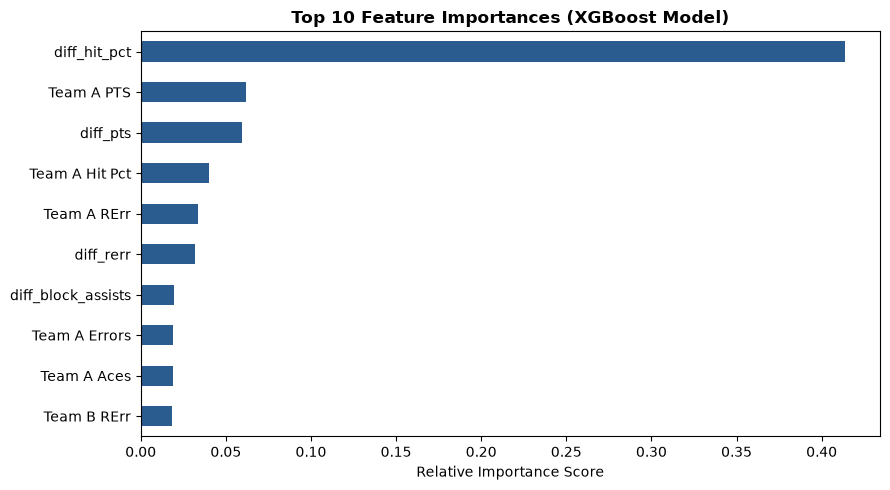

In [5]:
import joblib
import matplotlib.pyplot as plt

best_model = joblib.load("../models/best_model.joblib")
feat_imp = pd.Series(best_model.feature_importances_, index=best_model.feature_names_in_)
top10 = feat_imp.nlargest(10).sort_values()

plt.figure(figsize=(9, 5))
top10.plot(kind="barh", color="#2b5c8f")
plt.title("Top 10 Feature Importances (XGBoost Model)", fontsize=12, fontweight="bold")
plt.xlabel("Relative Importance Score", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Symmetrical Matchup Prediction Engine

Predict the winner and win probabilities between any two NCAA teams using their latest statistical profiles.
Predictions are evaluated symmetrically (averaging $A \text{ vs } B$ and $B \text{ vs } A$) to eliminate presentation order bias.

In [6]:
from src.predict import predict_matchup

res = predict_matchup("Stanford", "Texas",
                      model_path="../models/best_model.joblib",
                      features_path="../data/processed/features.csv")

print(f"=== Matchup Prediction: {res['team_a']} vs {res['team_b']} ===")
print(f"{res['team_a']} Win Chance : {res['prob_a']*100:.2f}%")
print(f"{res['team_b']} Win Chance    : {res['prob_b']*100:.2f}%")
print(f"Predicted Winner     : {res['predicted_winner']} ({res['confidence']*100:.1f}% confidence)\n")
print("Key Differentials (Team A - Team B):")
for stat, diff in res["key_differentials"].items():
    leader = res['team_a'] if diff > 0 else res['team_b']
    print(f"  - {stat:12s}: {diff:+.3f} (Advantage: {leader})")

=== Matchup Prediction: Stanford vs Texas ===
Stanford Win Chance : 56.61%
Texas Win Chance    : 43.39%
Predicted Winner     : Stanford (56.6% confidence)

Key Differentials (Team A - Team B):
  - Hit Pct     : +0.016 (Advantage: Stanford)
  - Kills       : -2.783 (Advantage: Texas)
  - Assists     : -2.141 (Advantage: Texas)
  - Digs        : +4.781 (Advantage: Stanford)
  - PTS         : -6.379 (Advantage: Texas)
